<a href="https://colab.research.google.com/github/fboldt/aulasann/blob/main/aula02c%20linear%20regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧠 Aula 02c: O Neurônio como Regressor Linear Contínuo

---

### 🎯 A Ponte entre Classificação e Regressão
Até agora, o neurônio usava a função degrau (`np.sign`) para tomar decisões de sim/não (+1 ou -1).  
**E se retirarmos a função degrau?**  
O neurônio passa a produzir saídas numéricas contínuas: $\hat{y} = X \cdot w + b$.  
Ele se transforma no clássico **Regressor Linear**, treinado com **Descida do Gradiente** e **Taxa de Aprendizado** (`learning_rate`)!



## 1. Dados de Regressão Contínua com Ruído


(20, 1) (20,)


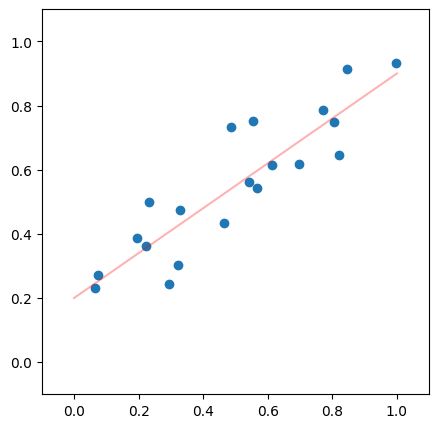

In [124]:
import numpy as np
import matplotlib.pyplot as plt

# Gerador de dados de regressão 1D com ruído gaussiano
def createRegressionDataset(n=20):
  X = np.random.rand(n, 1)
  coef = 0.7
  intercept = 0.2
  noise = np.random.randn(n, 1) * 0.1
  y = X * coef + intercept + noise
  return X, y.reshape(-1)

def plotDataset(X, y):
  plt.figure(figsize=(5,5))
  plt.scatter(X, y, color="blue", alpha=0.6)
  plt.xlim(-0.1, 1.1)
  plt.ylim(-0.1, 1.1)
  plt.xlabel("X")
  plt.ylabel("y")

def plotLine(coef, intercept, color="red"):
  xs = np.array([0, 1])
  ys = coef * xs + intercept
  plt.plot(xs, ys, c=color, alpha=0.5, label="Reta Real")
  plt.legend()

X, y = createRegressionDataset()
print("Formatos:", X.shape, y.shape)
plotDataset(X, y)
plotLine(0.7, 0.2)
plt.title("Dados de Regressão com Reta Real (y = 0.7x + 0.2)")
plt.show()


## 2. O Neurônio Treinado com Gradiente Descendente

> Como a saída é contínua, o erro é contínuo e usamos a **taxa de aprendizado** (`learning_rate=0.01`) para passos suaves.


RMSE: 0.0947927897015691
Weights: [0.70595911], Bias: 0.20361400617166964


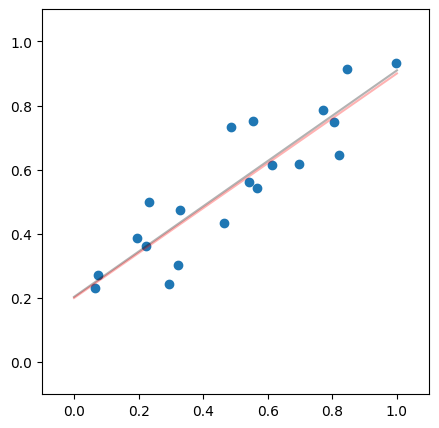

In [134]:
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.metrics import root_mean_squared_error

# Neurônio Linear com Gradiente Descendente Contínuo
class LinearRegression(BaseEstimator, ClassifierMixin):
  def __init__(self, max_iter=1000, learning_rate=0.01):
    self.max_iter = max_iter
    self.learning_rate = learning_rate

  def fit(self, X, y):
    self.w_ = np.random.rand(X.shape[1])
    self.b_ = np.random.rand()
    for _ in range(self.max_iter):
      y_pred = self.predict(X)                    # Saída contínua (sem sign)
      error = y - y_pred                          # Erro contínuo
      # Atualização suave multiplicada pela taxa de aprendizado
      self.w_ += np.dot(X.T, error) * self.learning_rate
      self.b_ += np.sum(error) * self.learning_rate
    return self

  def predict(self, X):
    return X @ self.w_ + self.b_

clf = LinearRegression()
clf.fit(X, y)
y_pred = clf.predict(X)
print(f"RMSE: {root_mean_squared_error(y, y_pred):.4f}")
print(f"Pesos aprendidos: {clf.w_}, Bias: {clf.b_}")
plotDataset(X, y)
plotLine(clf.w_, clf.b_, color="black")
plotLine(0.7, 0.2)
plt.title("Reta Aprendida (Preta) vs Real (Vermelha)")
plt.show()
